In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [36]:
EXPERIMENT_SIZES = [20, 30, 40, 50, 60, 70, 80, 90, 100]
STRATEGIES = ["fifo", "fwf", "lru", "lfu", "rand", "rma"]
DISTRIBUTIONS = [
    "uniform",
    "geometric",
    "harmonic",
    "biharmonic",
]
DISTRIBUTION_INDEXES = {
    "uniform": [0, 0],
    "geometric": [0, 1],
    "harmonic": [1, 0],
    "biharmonic": [1, 1],
}
STRATEGIES_INDEXES = {
    "fifo": [0, 0],
    "fwf": [0, 1],
    "lru": [1, 0],
    "lfu": [1, 1],
    "rand": [2, 0],
    "rma": [2, 1],
}

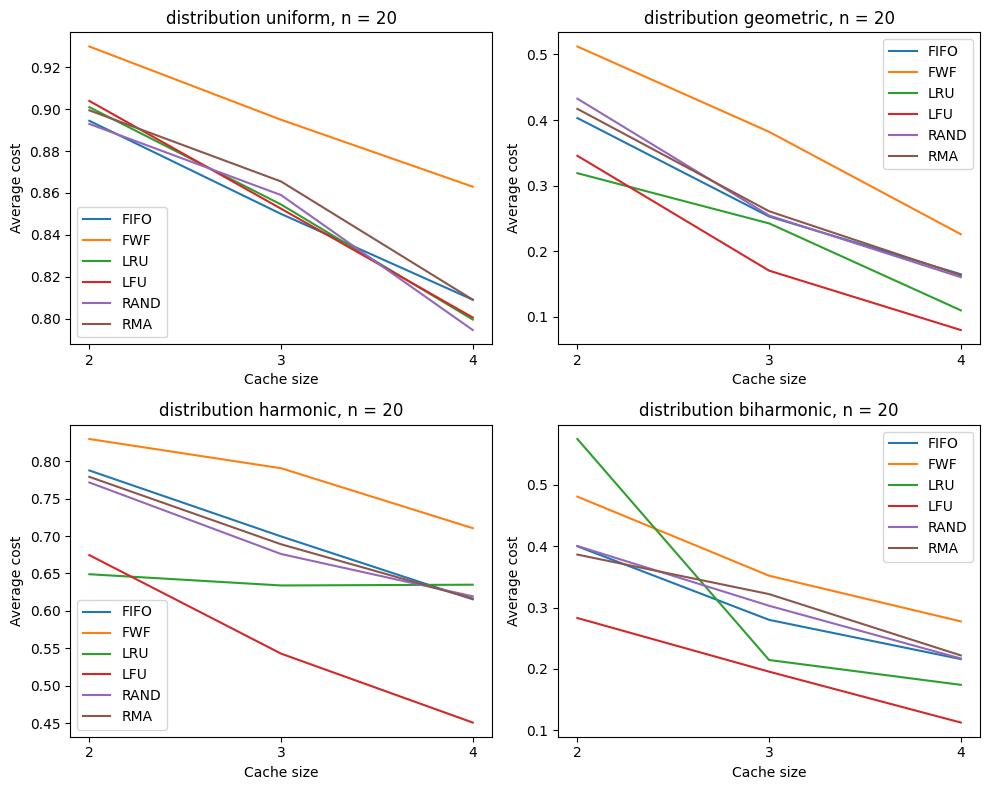

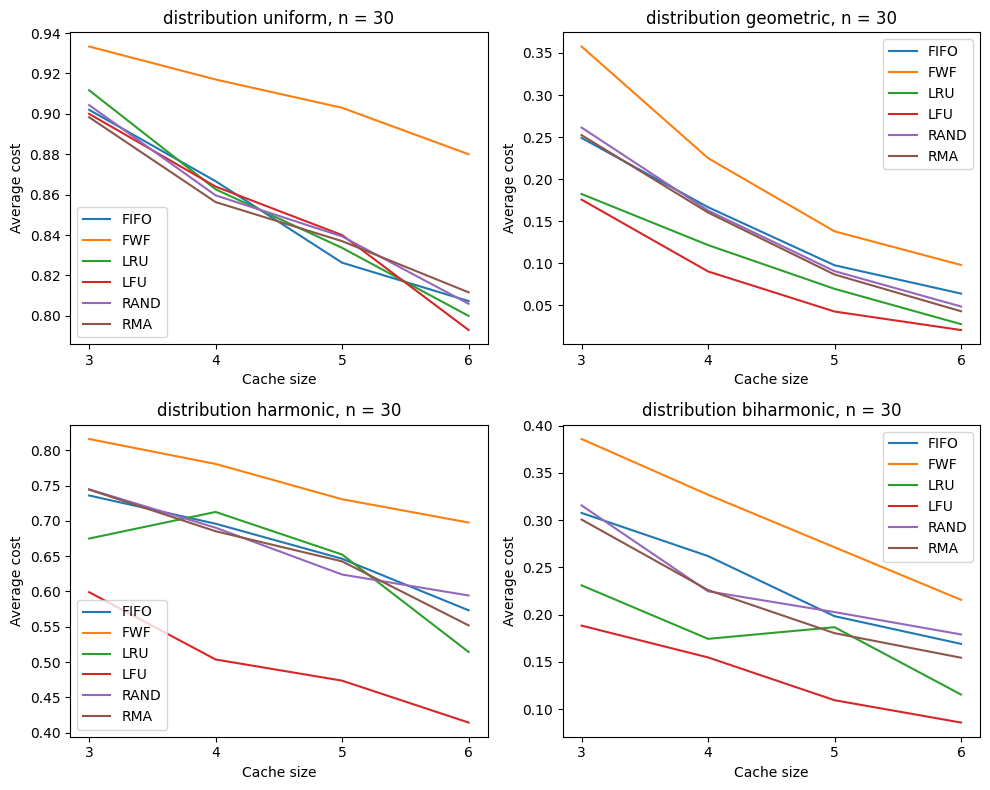

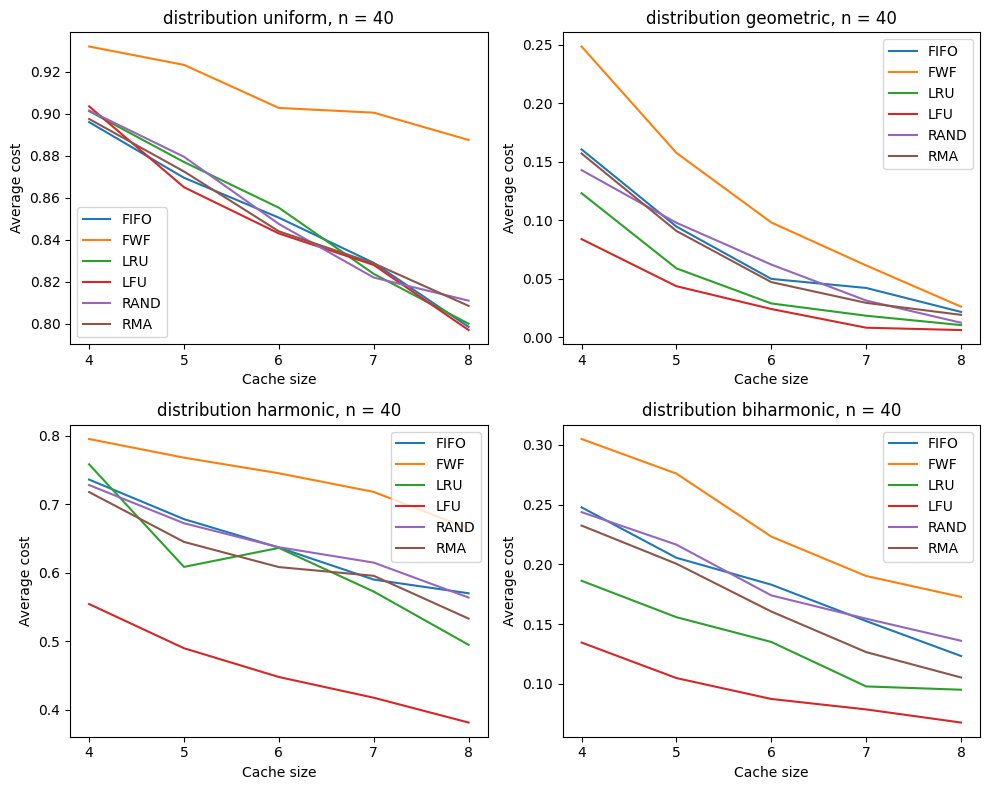

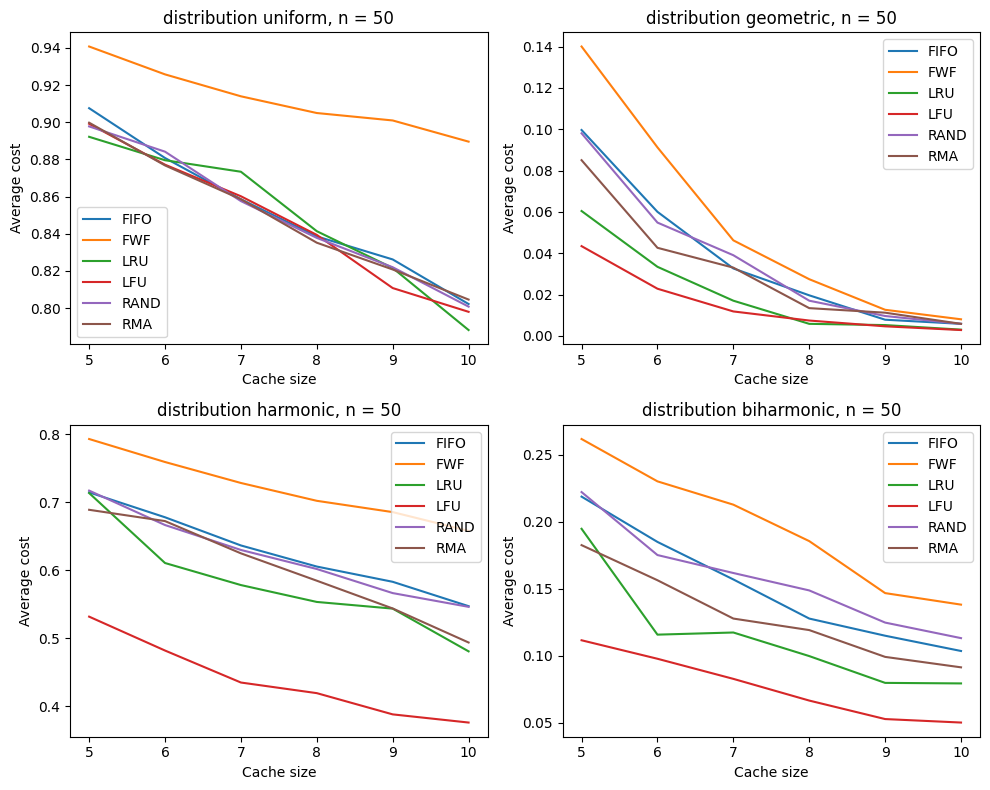

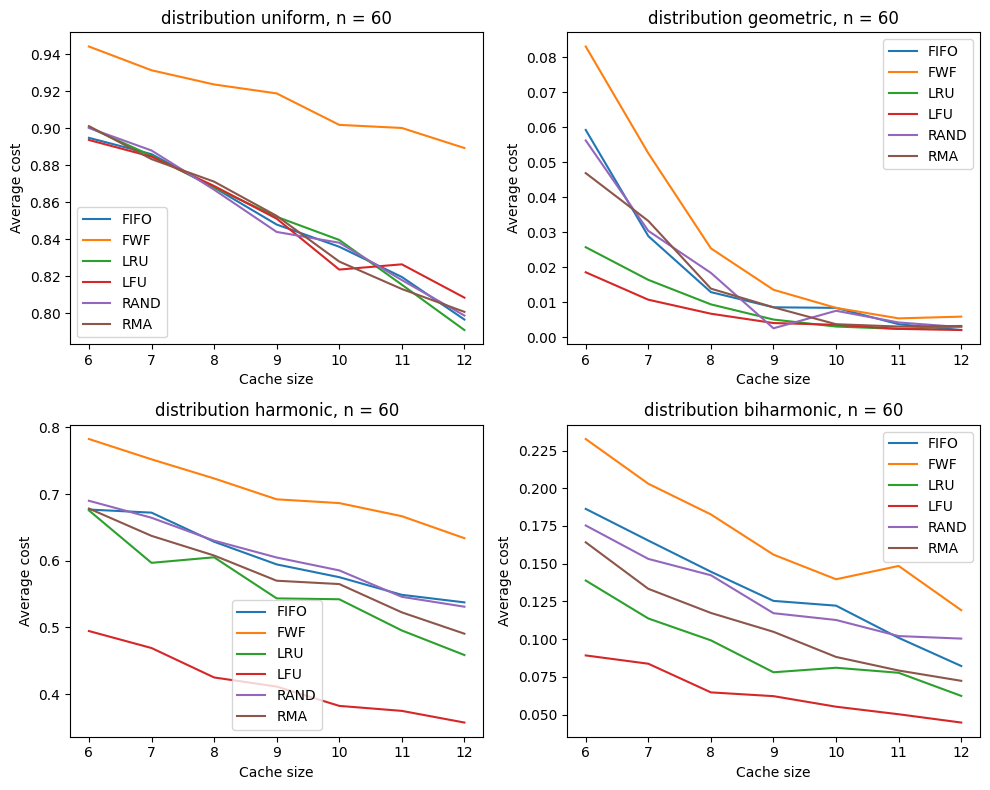

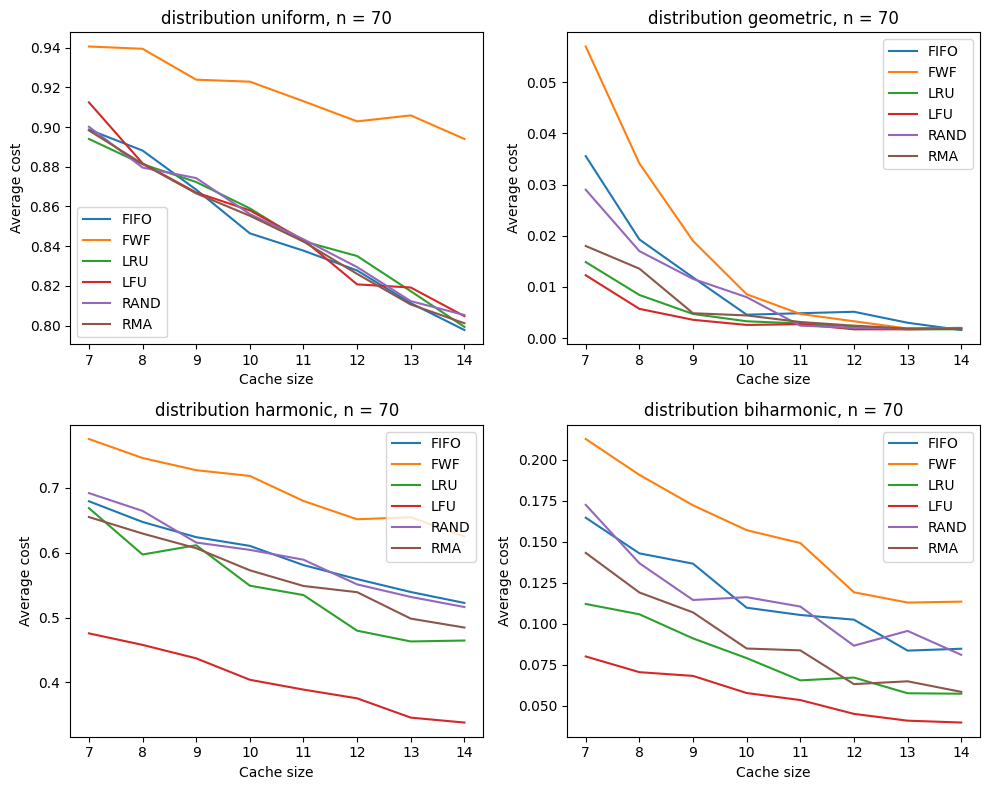

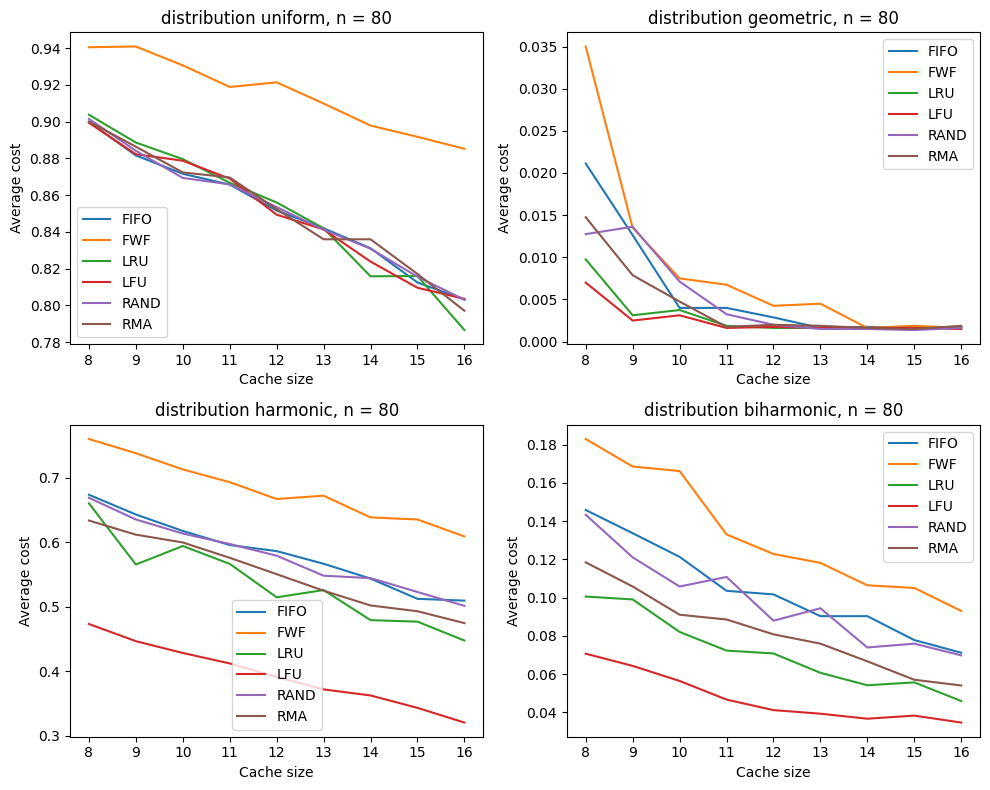

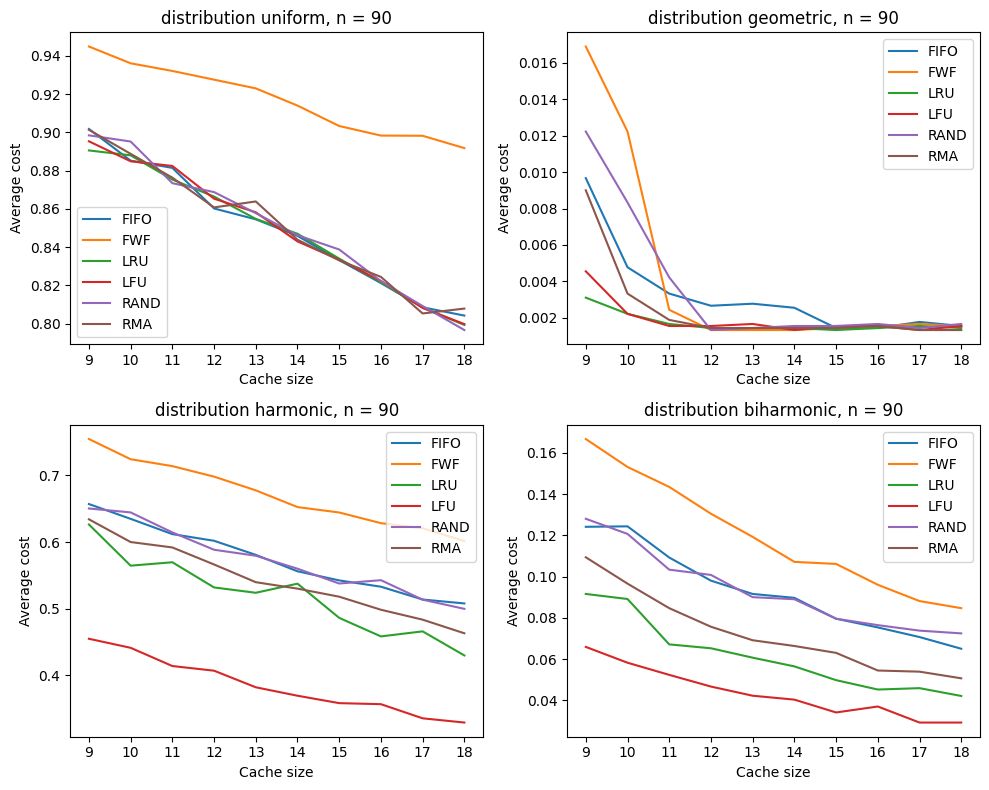

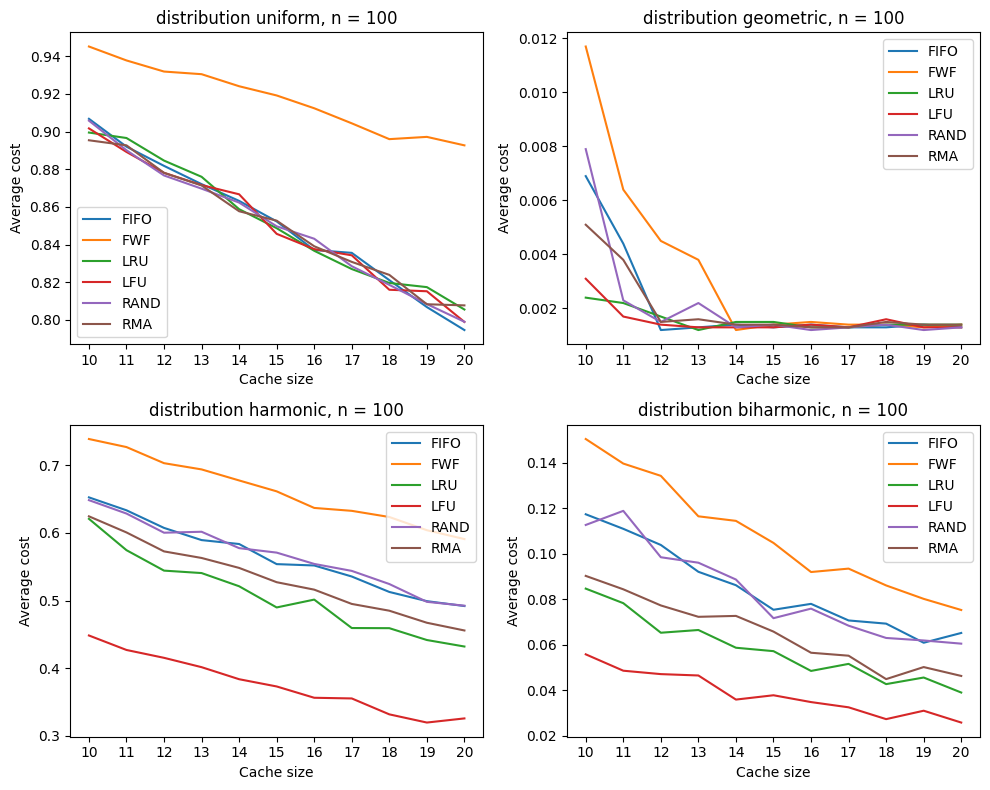

In [35]:
df = pd.read_csv("costs.csv", sep=";")

for n in EXPERIMENT_SIZES:
    fig, ax = plt.subplots(2, 2, figsize=(10, 8))
    for dist in DISTRIBUTIONS:
        df_dist_n = df[(df["distribution"] == dist) & (df["n"] == n)]
        row, col = DISTRIBUTION_INDEXES[dist]
        for strategy in STRATEGIES:
            ax[row, col].plot(
                df_dist_n["k"].unique(),
                df_dist_n[df_dist_n["strategy"] == strategy]["cost"],
                label=strategy.upper()
            )
        ax[row, col].set_title(f"distribution {dist}, n = {n}")
        ax[row, col].set_xticks(df_dist_n["k"].unique())
        ax[row, col].set_xlabel("Cache size")
        ax[row, col].set_ylabel("Average cost")
        ax[row, col].legend()
    plt.tight_layout()
    plt.show()

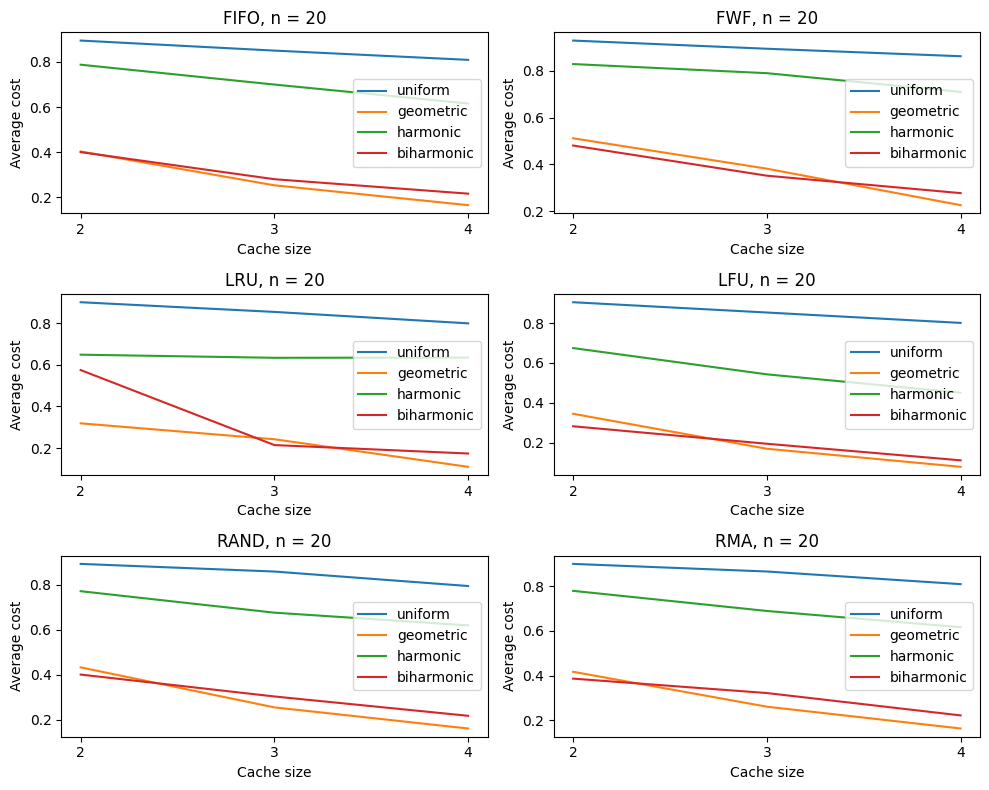

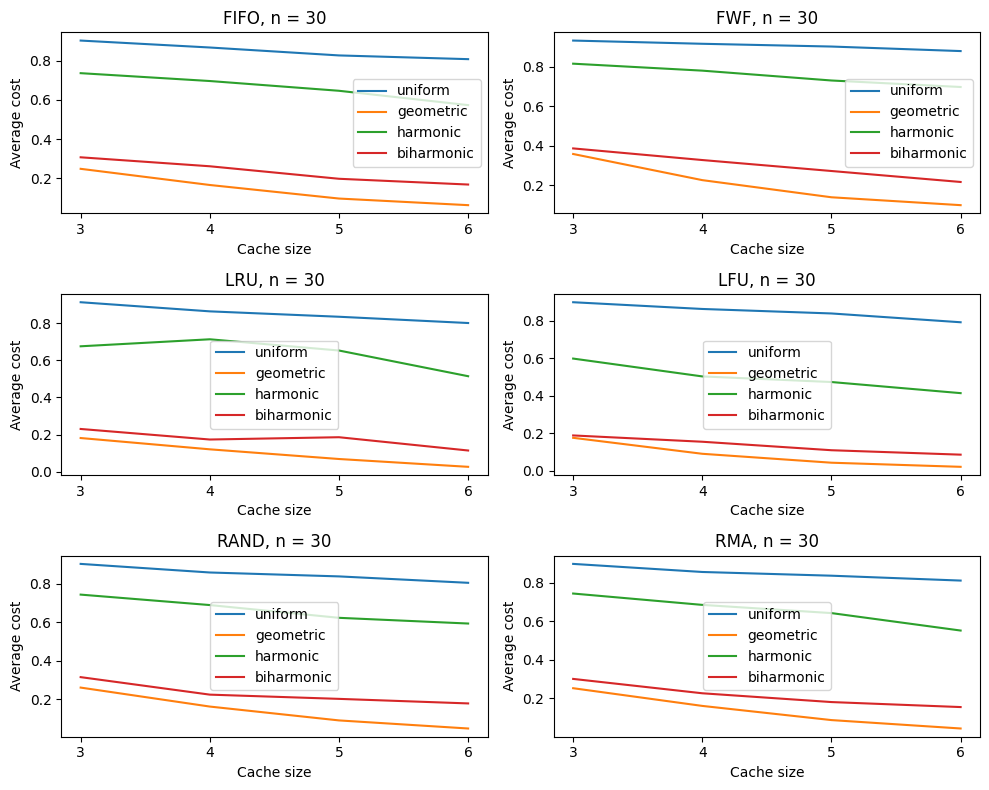

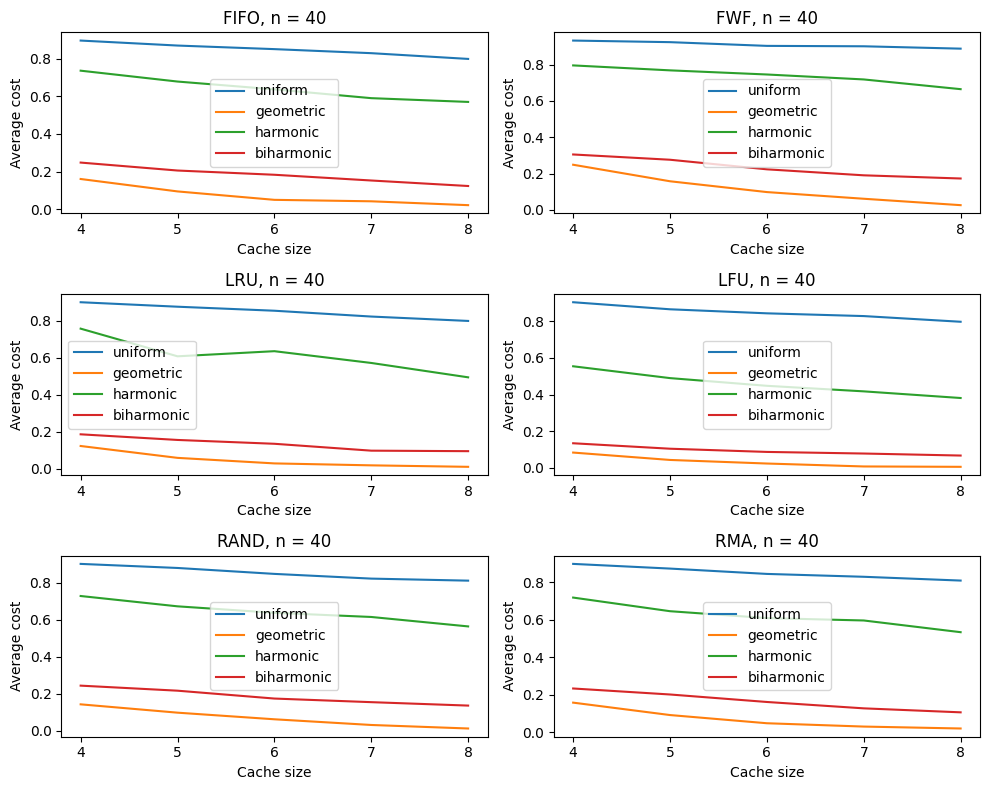

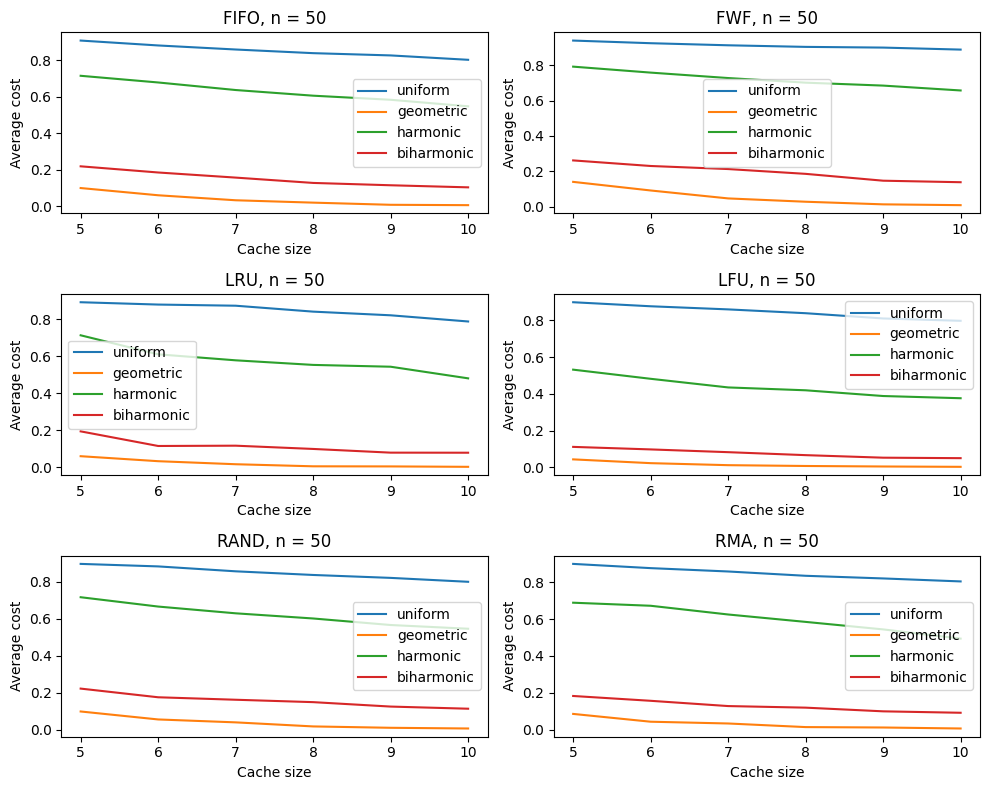

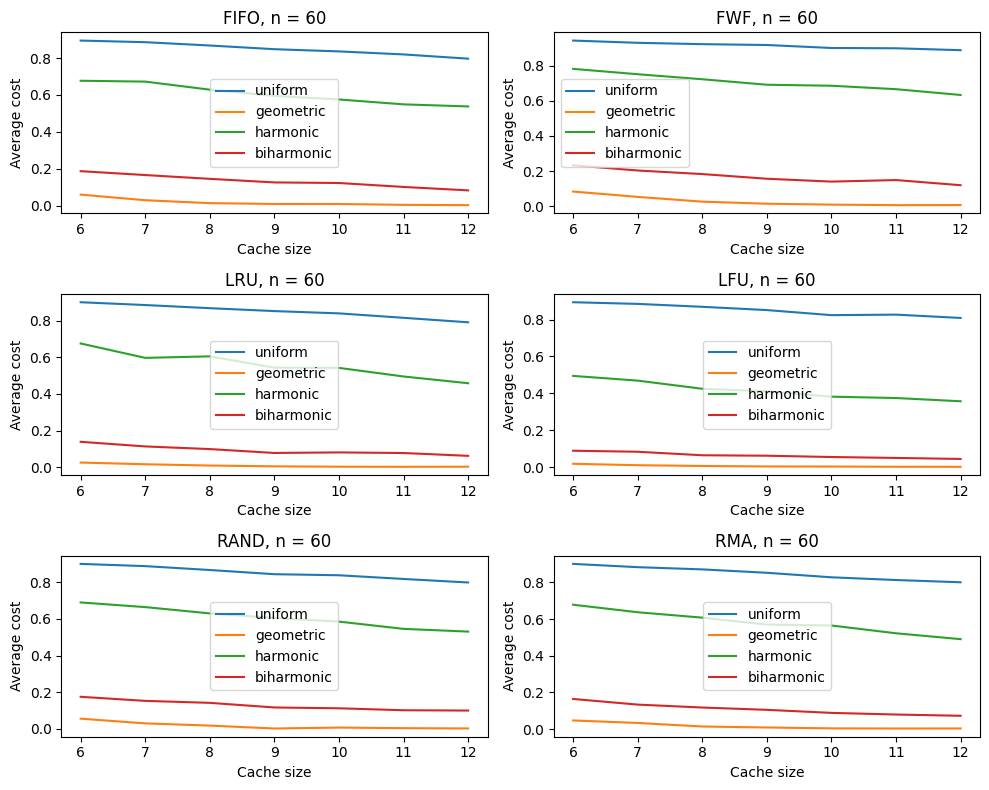

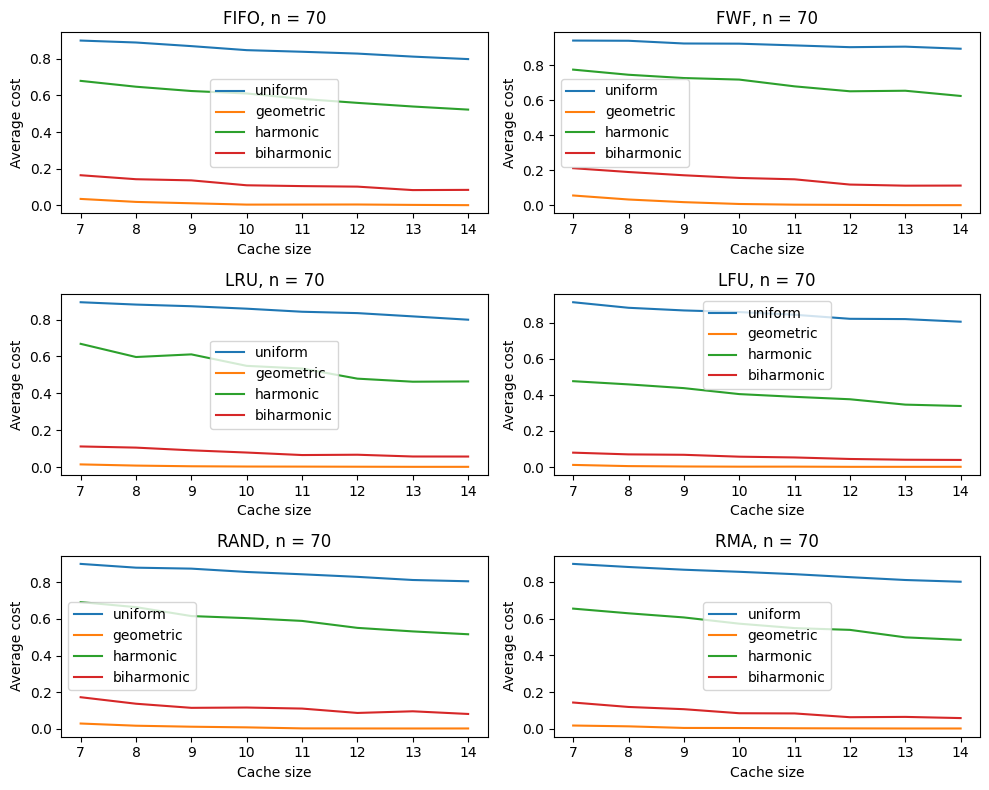

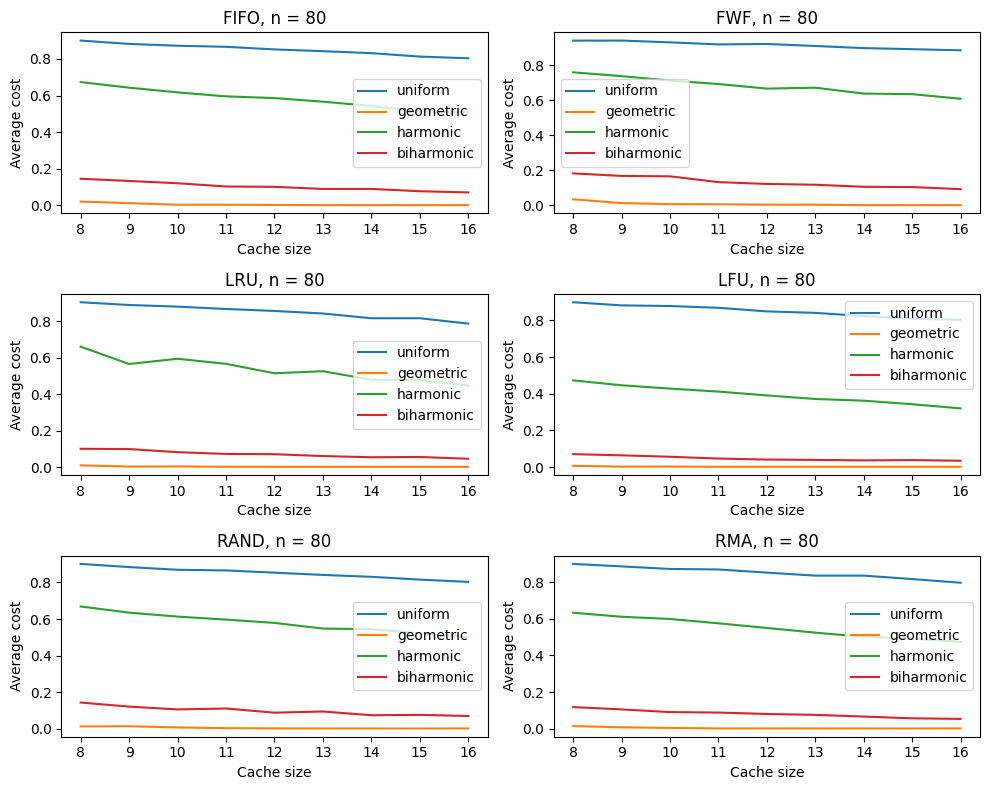

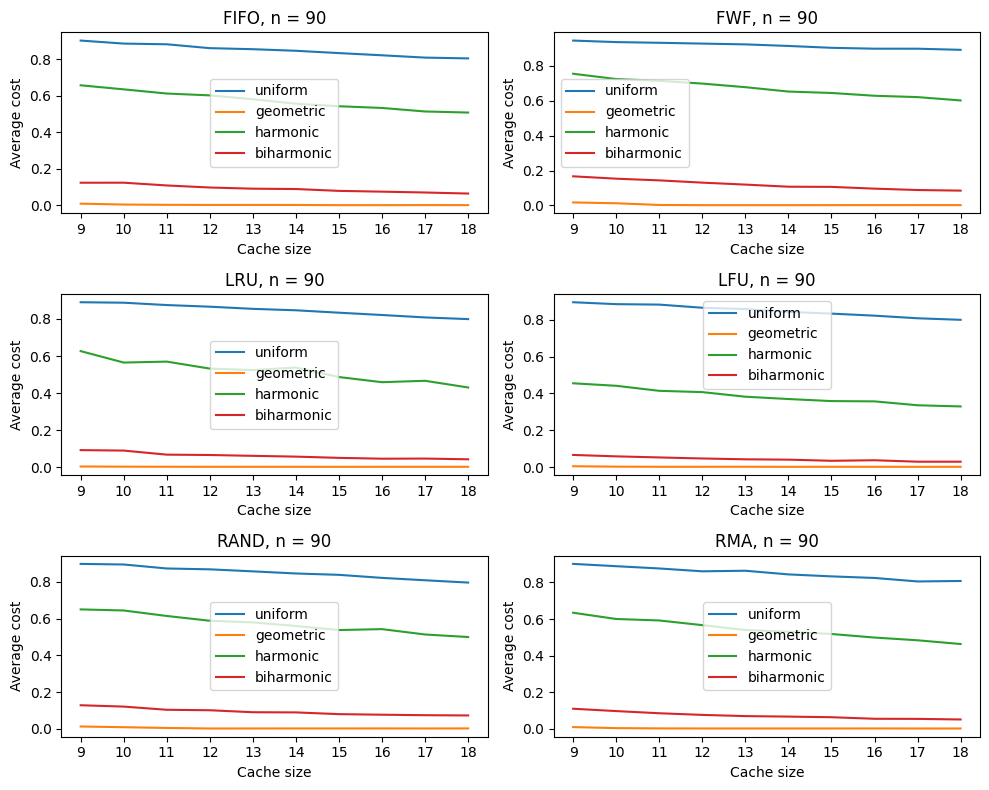

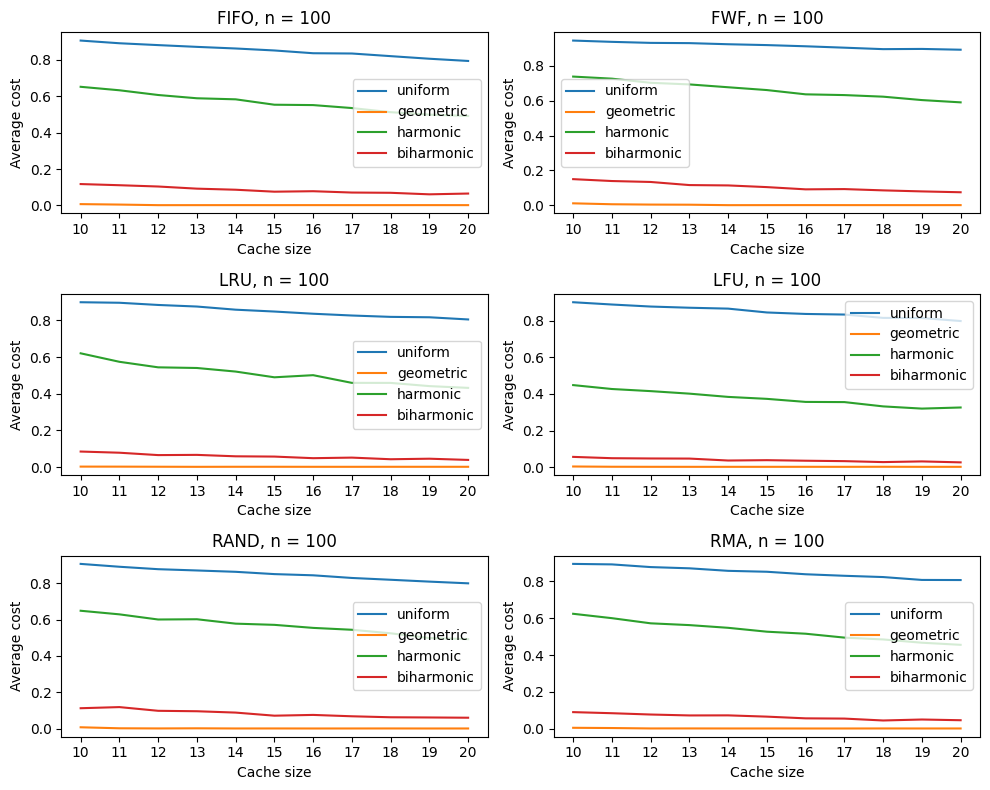

In [39]:
df = pd.read_csv("costs.csv", sep=";")

for n in EXPERIMENT_SIZES:
    fig, ax = plt.subplots(3, 2, figsize=(10, 8))
    for strategy in STRATEGIES:
        df_strat_n = df[(df["strategy"] == strategy) & (df["n"] == n)]
        row, col = STRATEGIES_INDEXES[strategy]
        for dist in DISTRIBUTIONS:
            ax[row, col].plot(
                df_strat_n["k"].unique(),
                df_strat_n[df_strat_n["distribution"] == dist]["cost"],
                label=dist
            )
        ax[row, col].set_title(f"{strategy.upper()}, n = {n}")
        ax[row, col].set_xticks(df_strat_n["k"].unique())
        ax[row, col].set_xlabel("Cache size")
        ax[row, col].set_ylabel("Average cost")
        ax[row, col].legend()
    plt.tight_layout()
    plt.show()